In [1]:
from pathlib import Path
from typing import Protocol, TypeAlias

from PIL import Image

import torch

from transformers import (
    AutoProcessor,
    Florence2ForConditionalGeneration,
)

from transformers import Sam2Model, Sam2Processor


BBox: TypeAlias = tuple[int, int, int, int]

In [3]:
class CharacterLocator(Protocol):
    """Locates a requested character within an image."""

    def locate(
        self,
        image: Image.Image,
        prompt: str,
    ) -> BBox:
        """
        Locate a character and return its bounding box.

        Args:
            image: Source image.
            prompt: Character description such as "the vampire".

        Returns:
            Bounding box as (left, top, right, bottom).
        """
        ...

In [4]:
class CharacterSegmenter(Protocol):
    """Segments a character using a supplied bounding box."""

    def segment(
        self,
        image: Image.Image,
        bbox: BBox,
    ) -> Image.Image:
        """
        Produce a binary mask for the character inside `bbox`.

        Args:
            image: Source image.
            bbox: Character bounding box.

        Returns:
            Grayscale PIL mask where white represents the character
            and black represents the background.
        """
        ...

class BackgroundStrategy(Protocol):
    """Defines how the segmented character background is handled."""

    def apply(
        self,
        image: Image.Image,
        mask: Image.Image,
    ) -> Image.Image:
        """Apply background handling using the segmentation mask."""
        ...

In [5]:
class TransparentBackgroundStrategy:
    """Replace the background with transparency."""

    def apply(
        self,
        image: Image.Image,
        mask: Image.Image,
    ) -> Image.Image:
        result = image.convert("RGBA")
        result.putalpha(mask)

        return result

class SolidBackgroundStrategy:
    """Replace the background with a solid color."""

    def __init__(
        self,
        color: str | tuple[int, int, int] = "white",
    ) -> None:
        self.color = color

    def apply(
        self,
        image: Image.Image,
        mask: Image.Image,
    ) -> Image.Image:
        image = image.convert("RGB")

        background = Image.new(
            mode="RGB",
            size=image.size,
            color=self.color,
        )

        return Image.composite(
            image,
            background,
            mask,
        )

In [7]:
def pad_bbox(
    bbox: BBox,
    image_size: tuple[int, int],
    padding: int = 10,
) -> BBox:
    """
    Add padding around a bounding box without exceeding image bounds.

    Args:
        bbox: Bounding box as (left, top, right, bottom).
        image_size: Image size as (width, height).
        padding: Pixels added to each side.

    Returns:
        Padded bounding box.
    """
    left, top, right, bottom = bbox
    width, height = image_size

    return (
        max(0, left - padding),
        max(0, top - padding),
        min(width, right + padding),
        min(height, bottom + padding),
    )

In [11]:
class Florence2CharacterLocator:
    """
    Uses Florence-2 caption-to-phrase grounding to locate a character.

    Given an image and phrase such as "the vampire", returns a bounding
    box in (left, top, right, bottom) format.
    """

    TASK_PROMPT = "<CAPTION_TO_PHRASE_GROUNDING>"

    def __init__(
        self,
        model_name: str = "florence-community/Florence-2-base",
        device: str | None = None,
    ) -> None:
        """
        Load Florence-2 using the native Transformers implementation.

        Args:
            model_name: Hugging Face Florence-2 checkpoint.
            device: Torch device. Automatically selects CUDA when available.
        """
        self.device = device or (
            "cuda" if torch.cuda.is_available() else "cpu"
        )

        self.dtype = (
            torch.float16
            if self.device == "cuda"
            else torch.float32
        )

        self.processor = AutoProcessor.from_pretrained(model_name)

        self.model = (
            Florence2ForConditionalGeneration
            .from_pretrained(
                model_name,
                dtype=self.dtype,
            )
            .to(self.device)
        )

        self.model.eval()

    @staticmethod
    def _bbox_area(bbox: BBox) -> int:
        """Return the area of a bounding box."""
        left, top, right, bottom = bbox

        return max(0, right - left) * max(0, bottom - top)

    def _select_bbox(
        self,
        parsed_output: dict,
    ) -> BBox:
        """
        Select a bounding box from Florence-2 output.

        For now, if multiple boxes are returned, choose the largest.
        """
        task_result = parsed_output.get(self.TASK_PROMPT)

        if task_result is None:
            raise ValueError(
                f"Florence-2 did not return results for "
                f"{self.TASK_PROMPT}.\n"
                f"Output: {parsed_output}"
            )

        bboxes = task_result.get("bboxes", [])

        if not bboxes:
            raise ValueError(
                "Florence-2 did not detect a matching character."
            )

        bboxes = [
            tuple(map(int, bbox))
            for bbox in bboxes
        ]

        return max(bboxes, key=self._bbox_area)

    def locate(
        self,
        image: Image.Image,
        prompt: str,
    ) -> BBox:
        """
        Locate a character described by `prompt`.

        Args:
            image: Source image.
            prompt: Character description, e.g. "the vampire".

        Returns:
            Bounding box as (left, top, right, bottom).
        """
        image = image.convert("RGB")

        # Florence phrase grounding expects:
        #
        # <CAPTION_TO_PHRASE_GROUNDING>the vampire
        #
        model_prompt = self.TASK_PROMPT + prompt

        inputs = self.processor(
            text=model_prompt,
            images=image,
            return_tensors="pt",
        )

        # Move tensors to the same device as the model.
        inputs = {
            key: (
                value.to(self.device, dtype=self.dtype)
                if value.is_floating_point()
                else value.to(self.device)
            )
            for key, value in inputs.items()
        }

        with torch.inference_mode():
            generated_ids = self.model.generate(
                **inputs,
                max_new_tokens=256,
                num_beams=3,
                do_sample=False,
            )

        generated_text = self.processor.batch_decode(
            generated_ids,
            skip_special_tokens=False,
        )[0]

        parsed_output = self.processor.post_process_generation(
            generated_text,
            task=self.TASK_PROMPT,
            image_size=image.size,
        )

        return self._select_bbox(parsed_output)

In [6]:
class SAM2CharacterSegmenter:
    """
    Segments a character using SAM 2.1 and a bounding-box prompt.

    The bounding box is expected to come from a CharacterLocator,
    such as Florence2CharacterLocator.
    """

    def __init__(
        self,
        model_name: str = "facebook/sam2.1-hiera-tiny",
        device: str | None = None,
    ) -> None:
        """
        Load SAM 2.1 Tiny.

        Args:
            model_name: Hugging Face SAM 2 checkpoint.
            device: Torch device. Automatically uses CUDA when available.
        """
        self.device = device or (
            "cuda" if torch.cuda.is_available() else "cpu"
        )

        self.processor = Sam2Processor.from_pretrained(model_name)

        self.model = (
            Sam2Model
            .from_pretrained(model_name)
            .to(self.device)
        )

        self.model.eval()

    def segment(
        self,
        image: Image.Image,
        bbox: BBox,
    ) -> Image.Image:
        """
        Segment the character contained within a bounding box.

        Args:
            image: Source image.
            bbox: Bounding box as (left, top, right, bottom).

        Returns:
            Binary grayscale PIL mask.
        """
        image = image.convert("RGB")

        # SAM expects:
        # batch -> objects -> [x1, y1, x2, y2]
        input_boxes = [[list(map(float, bbox))]]

        inputs = self.processor(
            images=image,
            input_boxes=input_boxes,
            return_tensors="pt",
        ).to(self.device)

        with torch.inference_mode():
            outputs = self.model(
                **inputs,
                multimask_output=False,
            )

        # Resize SAM's mask back to the original image dimensions.
        masks = self.processor.post_process_masks(
            outputs.pred_masks.cpu(),
            inputs["original_sizes"],
        )[0]

        # One bounding box + multimask_output=False means we want
        # the first object's first mask.
        mask_tensor = masks[0, 0]

        # Convert boolean/binary tensor into a PIL grayscale mask.
        mask_array = (
            mask_tensor
            .to(torch.uint8)
            .numpy()
            * 255
        )

        return Image.fromarray(mask_array, mode="L")

In [8]:
class CharacterReferenceExtractor:
    """
    Creates clean character-reference images.

    Pipeline:
        1. Locate character.
        2. Segment character.
        3. Apply selected background strategy.
        4. Tightly crop around the segmentation mask.
    """

    def __init__(
        self,
        locator: CharacterLocator,
        segmenter: CharacterSegmenter,
        background_strategy: BackgroundStrategy,
        padding: int = 10,
    ) -> None:
        self.locator = locator
        self.segmenter = segmenter
        self.background_strategy = background_strategy
        self.padding = padding

    def extract(
        self,
        image: Image.Image,
        prompt: str,
    ) -> Image.Image:
        """Locate, segment, and extract a character reference."""
        image = image.convert("RGB")

        bbox = self.locator.locate(
            image=image,
            prompt=prompt,
        )

        mask = self.segmenter.segment(
            image=image,
            bbox=bbox,
        )

        mask_bbox = mask.getbbox()

        if mask_bbox is None:
            raise ValueError(
                f"SAM 2 returned an empty mask for prompt: {prompt!r}"
            )

        crop_bbox = pad_bbox(
            bbox=mask_bbox,
            image_size=image.size,
            padding=self.padding,
        )

        isolated_character = self.background_strategy.apply(
            image=image,
            mask=mask,
        )

        return isolated_character.crop(crop_bbox)

    def extract_from_file(
        self,
        image_path: str | Path,
        prompt: str,
    ) -> Image.Image:
        """Extract a character from an image file."""
        image = Image.open(image_path).convert("RGB")

        return self.extract(
            image=image,
            prompt=prompt,
        )

    def extract_and_save(
        self,
        image_path: str | Path,
        output_path: str | Path,
        prompt: str,
    ) -> Image.Image:
        """Extract and save a character reference."""
        character_ref = self.extract_from_file(
            image_path=image_path,
            prompt=prompt,
        )

        output_path = Path(output_path)
        output_path.parent.mkdir(
            parents=True,
            exist_ok=True,
        )

        character_ref.save(output_path)

        return character_ref

In [20]:
locator = Florence2CharacterLocator()

segmenter = SAM2CharacterSegmenter()

extractor = CharacterReferenceExtractor(
    locator=locator,
    segmenter=segmenter,
    background_strategy=TransparentBackgroundStrategy(),
    # background_strategy=SolidBackgroundStrategy("blue"),
    padding=0,
)

Loading weights:   0%|          | 0/665 [00:00<?, ?it/s]

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Image size: (509, 510)
Florence bbox: (57, 73, 455, 496)
Mask size: (509, 510)


/tmp/ipykernel_9408/1246332352.py:86: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(mask_array, mode="L")


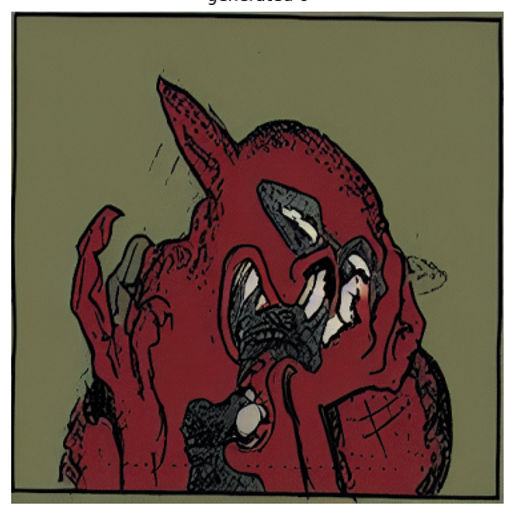

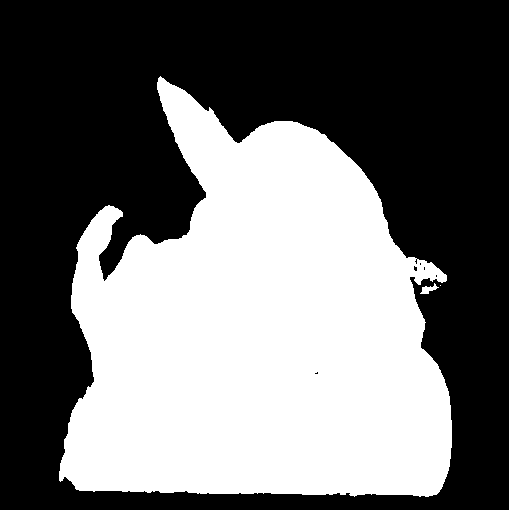

In [21]:
image = Image.open("panel0.png").convert("RGB")

bbox = locator.locate(
    image,
    "the vampire",
)

mask = segmenter.segment(
    image,
    bbox,
)

print("Image size:", image.size)
print("Florence bbox:", bbox)
print("Mask size:", mask.size)

display(image)
display(mask)

Reference size: (393, 421)


/tmp/ipykernel_9408/1246332352.py:86: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(mask_array, mode="L")


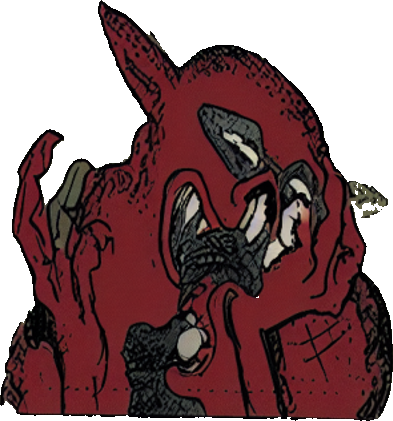

In [26]:
character_ref = extractor.extract_and_save(
    image_path="panel0.png",
    output_path="character_refs/vampire_ref.png",
    prompt="the vampire",
)

print("Reference size:", character_ref.size)

display(character_ref)

Reference size: (317, 321)


/tmp/ipykernel_9408/1246332352.py:86: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(mask_array, mode="L")


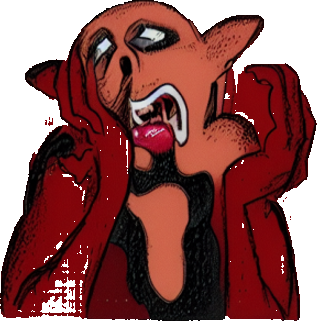

In [27]:
character_ref = extractor.extract_and_save(
    image_path="panel2.png",
    output_path="character_refs/vampire_ref.png",
    prompt="the vampire",
)

print("Reference size:", character_ref.size)

display(character_ref)

Reference size: (319, 321)


/tmp/ipykernel_9408/1246332352.py:86: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(mask_array, mode="L")


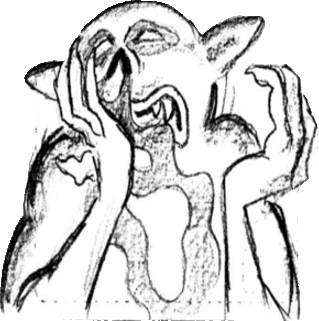

In [28]:
character_ref = extractor.extract_and_save(
    image_path="panel4_BW.png",
    output_path="character_refs/vampire_ref.png",
    prompt="the vampire",
)

print("Reference size:", character_ref.size)

display(character_ref)